In [40]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Simulating motion

### 1.1 Equations of motion (open loop)



$\ddot{x}=3n^2x + 2nv_y$

$\ddot{y}=-2nv_x$

$\ddot{z}=-n^2z$

with $n = 1.104\times10^{-3}$ rad/s (T = 94.8 min). Science station: follower 100 m behind the leader, $(x,y,z)=(0,-100,0)$ m

In [41]:
n = 1.104e-3 # [rad/s] mean motion, 510 km SSO (SR-01 baseline)

def get_acceleration(position, velocity, time): #can be angular position and angular velocity
    x,y,z = position #[m] follower relative to leader: x radial, y along-track, z cross-track
    vx,vy,vz = velocity # [m/s]

    ax = 3*n**2*x + 2*n*vy #Clohessy-Wiltshire equations of motion
    #m/s^2 = 1/s^2*m + 1/s*m/s    UNITS CHECK
    ay = -2*n*vx
    az = -n**2*z

    acceleration = np.array([ax, ay, az]) #[m/s^2] 
    return acceleration

### 1.2 Putting everything together

Text(0.5, 0, 'z cross-track [m]')

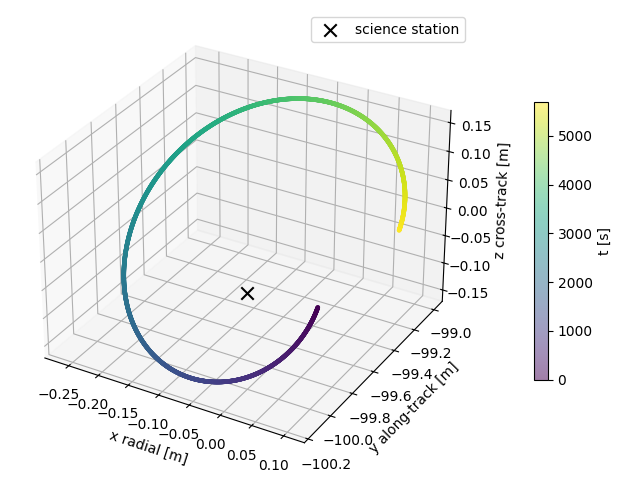

In [42]:
dt = 1
t_end = 5690 #[s] one orbit (94.8 min)

N = int(t_end/dt)
positions = np.empty((N, 3))
velocities = np.empty((N, 3))

r_target = np.array([0, -100, 0]) #[m] science station: follower 100 m behind the leader (MR-02 nominal)
positions[0] = r_target + np.random.normal(0,0.1,3) #IMPORTANT FOR TESTING
# velocities[0][1] = -2*n*(positions[0][0] - r_target[0])
velocities[0] = np.random.normal(0,0.25e-3,3)

for i in range(N-1):
    acceleration = get_acceleration(positions[i], velocities[i], i*dt)
    positions[i+1] = positions[i] + velocities[i]*dt
    velocities[i+1] = velocities[i] + acceleration*dt

ax = plt.figure(figsize=(8,6)).add_subplot(projection="3d") #3D view (leader is at the origin, 100 m in +y)
path = ax.scatter(positions[:,0], positions[:,1], positions[:,2], marker=".", alpha=0.5, c=np.arange(N)*dt) #color = time
ax.scatter(*r_target, color="k", marker="x", s=80, label="science station")
plt.colorbar(path, label="t [s]", shrink=0.6, pad=0.1)
plt.legend()
ax.set_xlabel("x radial [m]")
ax.set_ylabel("y along-track [m]")
ax.set_zlabel("z cross-track [m]")


### 1.3 Sanity check

The results shouldn't be sensitive to shoice of a simulation (non-physical) parameter $\Delta t$

Text(0, 0.5, 'y along-track [m]')

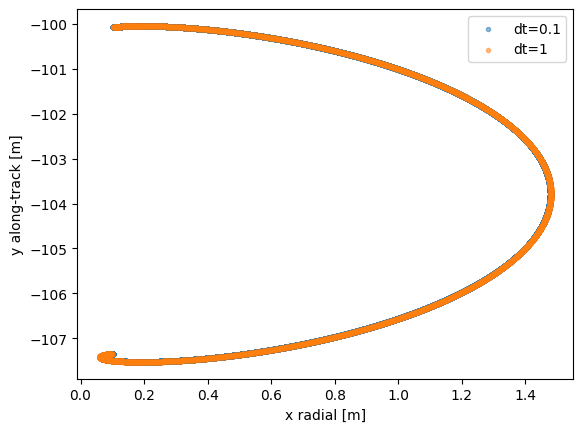

In [25]:
#fix random initial considtions
position_0 = r_target + np.random.normal(0,0.1,3)
velocity_0 = np.random.normal(0,0.25e-3,3)

for dt in [0.1, 1]: #simulate with two very different dt
    N = int(t_end/dt)
    positions = np.empty((N, 3))
    velocities = np.empty((N, 3))

    positions[0] = position_0
    velocities[0] = velocity_0

    for i in range(N-1):
        acceleration = get_acceleration(positions[i], velocities[i], i*dt)
        positions[i+1] = positions[i] + velocities[i]*dt
        velocities[i+1] = velocities[i] + acceleration*dt

    plt.scatter(positions[:,0], positions[:,1], marker=".", alpha=0.5, label=f"dt={dt}")

plt.legend()
plt.xlabel("x radial [m]")
plt.ylabel("y along-track [m]")

## 2 More realistic simulations (random processes)

### 2.1 Random forcing

In [26]:
def get_realistic_acceleration(position, velocity, time, a_std):
    acceleration = get_acceleration(position, velocity, time) #ideal

    random_acceleration = np.random.normal(0, a_std, acceleration.shape) #random acceleration with standard deviation of a_std and the same dimensions as the original acceleration

    return acceleration + random_acceleration

### 2.2 Comparison to the "ideal" case

Random acceleration propostional to $\frac{1}{\sqrt{\Delta t}}$ gives the "correct" behavior

Text(0, 0.5, 'y along-track [m]')

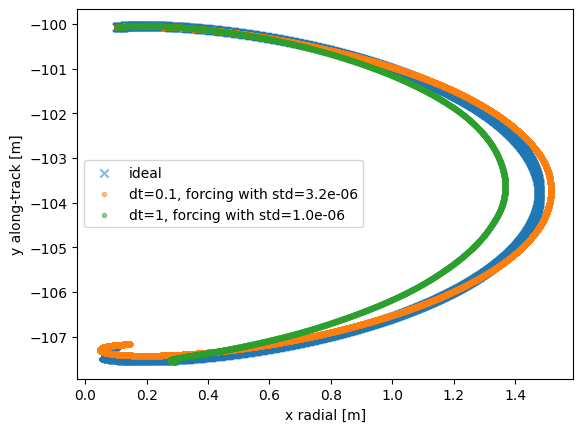

In [27]:
plt.scatter(positions[:,0], positions[:,1], marker="x", alpha=0.5, label="ideal")
A = 1e-6 #[m/s^(3/2)] acceleration noise spectral density: unmodeled differential drag/SRP (~1e-7 m/s^2, covered ~2x over one 30 s cycle; proposed)

for dt in [0.1, 1]:
    N = int(5690/dt) #remember to update number of points
    positions_w_rf = np.empty((N, 3))
    velocities_w_rf = np.empty((N, 3))

    positions_w_rf[0] = positions[0] 
    velocities_w_rf[0] = velocities[0]

    a_std = A/np.sqrt(dt) # this gives the correct results

    for i in range(N-1):
        acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
        positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
        velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label=f"dt={dt}, forcing with std={a_std:.1e}")

plt.legend()
plt.xlabel("x radial [m]")
plt.ylabel("y along-track [m]")

## 3. Measuring and filtering

### 3.1 Position only measuremnt 

In [28]:
positions_m = np.empty((N, 3)) #m for measured
sigma_xy = np.array([5.5e-3, 0.5e-3, 5.5e-3])/3 #[m] laser metrology error (1 sigma) [x, y, z]: lateral 55 urad x 100 m, range 0.5 mm (3-sigma values / 3)
#one reading per 1 s step (metrology runs at 10 Hz, SR-41, so using 1 in 10 readings is conservative)
    
for i in range(N):
    positions_m[i] = positions_w_rf[i] + np.random.normal(0, sigma_xy, positions_w_rf[i].shape)

#equivalant code:
#positions_m = np.random.normal(0, xy_std, positions_w_rf.shape)


Also plot position and error as a function of time

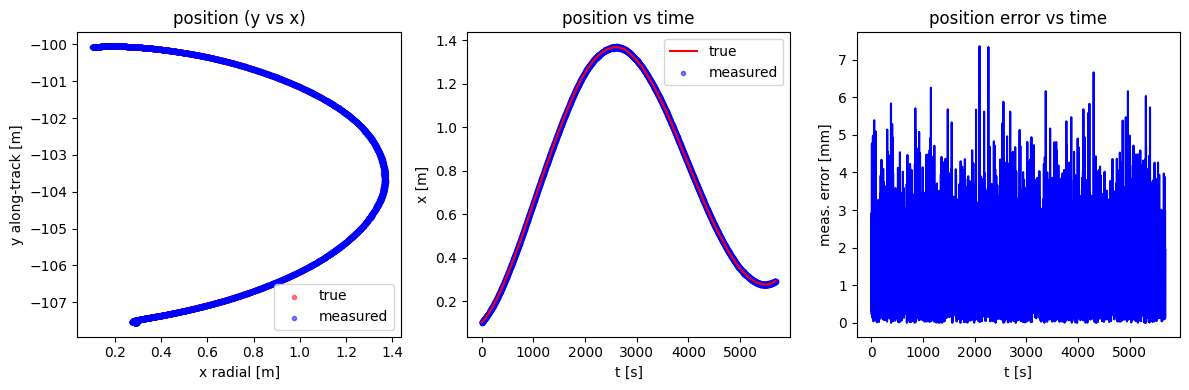

In [ ]:
plt.figure(figsize=(12,4)) #make figure larger
times = np.arange(N)*dt #an array of times [s]

plt.subplot(131) #first subplot of of 3 columns (one row)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label="true", color="r")
plt.scatter(positions_m[:,0], positions_m[:,1], marker=".", alpha=0.5, label="measured", color="b")
plt.legend()
plt.xlabel("x radial [m]")
plt.ylabel("y along-track [m]")
plt.title("position (y vs x)")
plt.subplot(132)
plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.scatter(times, positions_m[:,0], label="measured", color="b", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")
plt.subplot(133)
plt.plot(times, np.abs(positions_m[:,0] - positions_w_rf[:,0])*1e3, color="b")
plt.xlabel("t [s]")
plt.ylabel("meas. error [mm]")
plt.title("position error vs time")
plt.tight_layout()
#ensure true position vs measured vs relative

### 3.2 State estimation
utilizing the equations of motion for better estimation

In [30]:
def RMS(error_time_series):
    return np.sqrt(np.mean(np.sum(error_time_series**2, axis=-1)))

RMS postion error 1.030 mm
RMS velocity error 0.052 mm/s


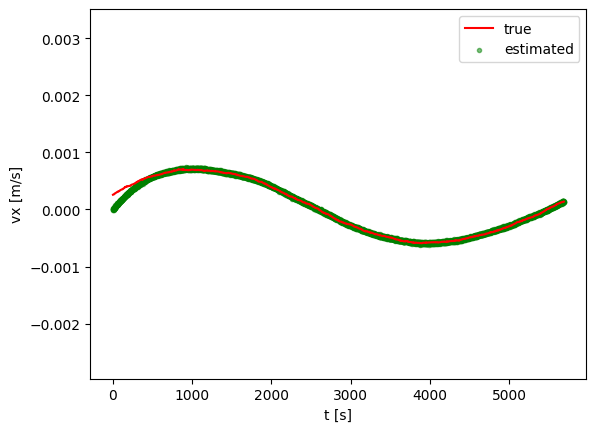

In [31]:
positions_est = np.zeros((N, 3))
velocities_est = np.zeros((N, 3))
positions_est[0] = positions_m[0] #start from the first laser reading

K_pos = 0.05 #position gain
K_vel = 0.005 #velocity gain (carefully picked for 1 s steps and the laser noise)

for i in range(N-1):
    #estimate acceleration using the equation of motion
    acceleration_est = get_acceleration(positions_est[i], velocities_est[i], i*dt)

    #predict position and velocity based on estimates
    position_prediction = positions_est[i] + velocities_est[i]*dt
    velocity_prediction = velocities_est[i] + acceleration_est*dt

    #old velocity estimate
    velocity_num_der = (positions_m[i+1] - positions_m[i])/dt
    #NOTE: if velocity is measured, take a weighted average fo the velocity measurement and the numerical derivative

    #update position and velocity based on measurement AND analytic prediction
    positions_est[i+1] = K_pos*positions_m[i+1] + (1-K_pos)*position_prediction
    velocities_est[i+1] = K_vel*velocity_num_der + (1-K_vel)*velocity_prediction



plt.plot(times, velocities_w_rf[:,0], label="true", color="r")
plt.scatter(times, velocities_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")
plt.ylim(velocities_w_rf[:,0].min()*5, velocities_w_rf[:,0].max()*5)

print(f"RMS postion error {RMS(positions_est - positions_w_rf)*1e3:.3f} mm")
print(f"RMS velocity error {RMS(velocities_est - velocities_w_rf)*1e3:.3f} mm/s")

### 3.3 How to choose gains using an Extended Kalman Filter (advanced)

#### 3.3.1 Rewrite as a state equation

$\mathbf{s}=\begin{bmatrix}x\\
y\\
z\\
v_{x}\\
v_{y}\\
v_{z}
\end{bmatrix}$

$\dot{\mathbf{s}}=\begin{bmatrix}\dot{x}\\
\dot{y}\\
\dot{z}\\
\ddot{x}\\
\ddot{y}\\
\ddot{z}
\end{bmatrix}=\begin{bmatrix}v_{x}\\
v_{y}\\
v_{z}\\
a_{x}\\
a_{y}\\
a_{z}
\end{bmatrix}=\begin{bmatrix}v_{x}\\
v_{y}\\
v_{z}\\
3n^{2}x+2nv_{y}\\
-2nv_{x}\\
-n^{2}z
\end{bmatrix}$

In discrete time:

$\mathbf{s}(t+\Delta t)\approx\mathbf{s}(t)+\dot{\mathbf{s}}(t)\Delta t $

or simply

$\mathbf{s}_{i+1} = \mathbf{f}(\mathbf{s}_i)$

#### 3.3.2 Find the linearized equation

$\mathbf{s}_{i+1}\approx F_{i}\mathbf{s}_{i})$

where $F_{i}=\left.\frac{\partial\mathbf{f}}{\partial\mathbf{s}}\right|_{\mathbf{s}_{i}}$ is the Jacobian at $\mathbf{s}_{i}$

the Jacobian is given by

$\frac{\partial\mathbf{f}}{\partial\mathbf{s}}=\begin{bmatrix}1 & 0 & 0 & dt & 0 & 0\\
0 & 1 & 0 & 0 & dt & 0\\
0 & 0 & 1 & 0 & 0 & dt\\
3n^{2}dt & 0 & 0 & 1 & 2ndt & 0\\
0 & 0 & 0 & -2ndt & 1 & 0\\
0 & 0 & -n^{2}dt & 0 & 0 & 1
\end{bmatrix}$

The Clohessy–Wiltshire equations are already linear, so $F$ does not depend on $\mathbf{s}$ and the linearized propagation matches exactly.

In [32]:
def f(s, dt):
    x,y,z,vx,vy,vz = s

    ax = 3*n**2*x + 2*n*vy
    ay = -2*n*vx
    az = -n**2*z

    return s + np.array([vx, vy, vz, ax, ay, az])*dt

def F(s, dt):
    x,y,z,vx,vy,vz = s
    
    return np.array([[         1,  0,         0,       dt,      0,  0], \
                     [         0,  1,         0,        0,     dt,  0], \
                     [         0,  0,         1,        0,      0, dt], \
                     [3*n**2*dt,  0,         0,        1, 2*n*dt,  0], \
                     [         0,  0,         0,  -2*n*dt,      1,  0], \
                     [         0,  0, -n**2*dt,        0,      0,  1]])


#### 3.3.3 Add process noise in state space

$\mathbf{s}_{i+1}=\mathbf{f}(\mathbf{s}_{i})+\mathbf{n}_{i}$ where $\mathbf{n}_{i}$ is normally distributed noise

In (2.1) we have:

random_acceleration = np.random.normal(0, a_std, acceleration.shape)

with a_std = A/np.sqrt(dt)

and then the random acceleration is multiplied by dt.

This is equivalent to adding np.random.normal(0, A*np.sqrt(dt), acceleration.shape) to the vecolity at each time step.

(the velocity makes random steps with standard deviation of A*np.sqrt(dt))

No forcing was directly applied to position.


The general form is 

$\mathbf{w}_{i}\sim{\cal N}\left(\mathbf{0},Q\right)$.

where $Q$ is the $6 \times 6$ covariance matrix

$Q=\begin{bmatrix}0\\
 & 0\\
 &  & 0\\
 &  &  & A^{2}\Delta t\\
 &  &  &  & A^{2}\Delta t\\
 &  &  &  &  & A^{2}\Delta t
\end{bmatrix}$

(the diagonal is the variance of the forcing --  the square of the standard deviation).

In code:


In [33]:
def realistic_f(s, A, dt):
    Q = np.diag([0, 0, 0, A**2*dt, A**2*dt, A**2*dt])
    w = np.random.multivariate_normal(np.zeros(6), Q)

    return f(s, dt) + w

#### 3.3.4 Rewrite the measurement equation and noise

$\mathbf{z}_i = \mathbf{h}(\mathbf{s}_{i})  + \mathbf{v}_i$

Previously we had

$\mathbf{h}(\mathbf{s}_{i})=\begin{bmatrix}x\\
y\\
z
\end{bmatrix}$

(the laser gives range along y and two lateral angles; at 100 m the angles × range are the lateral positions x and z)

This particular measurement equation does not need to be linearized since it can already be written as

$\mathbf{z}_{i}=H\mathbf{s}_{i}+\mathbf{v}_{i}$

with

$H=\begin{bmatrix}1 & 0 & 0 & 0 & 0 & 0\\
0 & 1 & 0 & 0 & 0 & 0\\
0 & 0 & 1 & 0 & 0 & 0
\end{bmatrix}$

The three componenets of $\mathbf{v}_i$ were normally distributed with standard deviations $\sigma_{x},\sigma_{y},\sigma_{z}$ (sigma_xy in the code).

This can be written as

$\mathbf{v}_{i}\sim{\cal N}\left(\mathbf{0},R\right)$

where

$R=\begin{bmatrix}\sigma_{x}^{2}\\
 & \sigma_{y}^{2}\\
 &  & \sigma_{z}^{2}
\end{bmatrix}$


In [34]:
H = np.array([[1,0,0,0,0,0], [0,1,0,0,0,0], [0,0,1,0,0,0]])
R = np.diag(sigma_xy**2)

#### 3.3.5 Define uncertaity in the initial condition

We had

position_0 = r_target + np.random.normal(0,0.1,3)
velocity_0 = np.random.normal(0,0.25e-3,3)

there for

$\mathbf{s}_{0}\sim{\cal N}\left(\mathbf{s}_{\mathrm{station}},\mathrm{diag}(0.1^2,0.1^2,0.1^2,(0.25\times10^{-3})^2,\ldots)\right)$, with $\mathbf{s}_{\mathrm{station}} = (0,-100,0,0,0,0)$.

The filter starts from the first laser reading $\mathbf{z}_0$ instead (better than the station guess), so $\hat{\mathbf{s}}_{0|0} = (\mathbf{z}_0, 0, 0, 0)$ and

$P_{0|0}=\begin{bmatrix}\sigma_{x}^{2}\\
 & \sigma_{y}^{2}\\
 &  & \sigma_{z}^{2}\\
 &  &  & (0.25\times10^{-3})^{2}\\
 &  &  &  & (0.25\times10^{-3})^{2}\\
 &  &  &  &  & (0.25\times10^{-3})^{2}
\end{bmatrix}$

#### 3.3.6 the Apply Kalman Filter equations

The *estimate* of the state is denoted with a "hat",  $\hat{\mathbf{s}}$. The state $\mathbf{s}$ is *unknown* to the estimator; it's only know in simulation or not at all (when deployed).

In our case, the estimate starts at the first laser reading, $\hat{\mathbf{s}}_{0|0} = (\mathbf{z}_0, \mathbf{0})$.

It is advanced in two steps.

a) The next state $\hat{\mathbf{s}}_{i+1|i}$ is predicted based on the previous state $\hat{\mathbf{s}}_{i|i}$:

$\hat{\mathbf{s}}_{i+1|i}=\mathbf{f}(\hat{\mathbf{s}}_{i|i})$

The uncertainty in the predicted state alos needs to be propagated forward:

$P_{i+1|i}=F_{i}P_{i|i}F_{i}^{T}+Q$

b) The next estimate $\hat{\mathbf{s}}_{i+1|i+1}$ is updated based on the pediction $\hat{\mathbf{s}}_{i+1|i}$ and the measurement $\mathbf{z_{i+1}}$:

First, compute the gain (Kalamn gain),

$K_{i+1} = P_{i+1|i}H^{T}S^{-1}_{i+1}$

where

$S_{i+1} = HP_{i+1|i}H^{T} + R$.

Then update the state

$\hat{\mathbf{s}}_{i+1|i+1}=\hat{\mathbf{s}}_{i+1|i}+K_{i+1}\left(\mathbf{z}_{i+1}-\mathbf{h}\left(\hat{\mathbf{s}}_{i+1|i}\right)\right)$,

and finally, update the convariance matrix

$P_{i+1|i+1} = P_{i+1|i+1} - K_{i+1}HP_{i+1|i}$.

Text(0, 0.5, 'y along-track [m]')

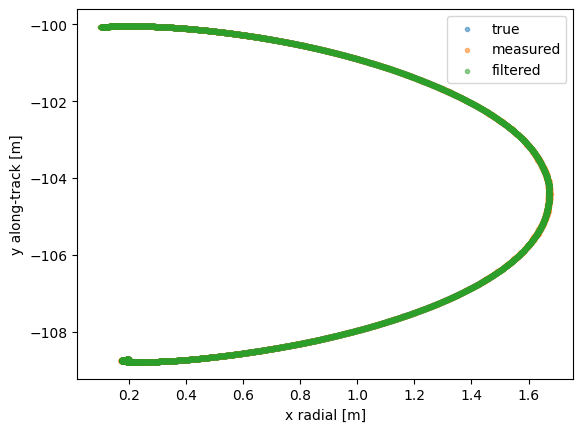

In [35]:
A = 1e-6 #[m/s^(3/2)] proportion constant (called acceleration noise spectral density)

dt = 1
N = int(5690/dt) #remember to update number of points
states_w_rf = np.empty((N,6))
states_est = np.empty((N,6)) #est for estimate

states_w_rf[0,:3] = positions[0] 
states_w_rf[0,3:6] = velocities[0]

measurements = np.zeros((N,3))
measurements[0] = H.dot(states_w_rf[0]) + np.random.multivariate_normal(np.zeros(3), R)

states_est[0,:3] = measurements[0] #this is the prior (first laser reading)
states_est[0,3:6] = 0

P = np.diag([sigma_xy[0]**2, sigma_xy[1]**2, sigma_xy[2]**2, 0.25e-3**2, 0.25e-3**2, 0.25e-3**2])
Q = np.diag([0, 0, 0, A**2*dt, A**2*dt, A**2*dt])

a_std = A/np.sqrt(dt) #[m/s^2] fixed acceleration (this gives wrong results)

for i in range(N):
    state_pred = f(states_est[i], dt)
    F_est = F(states_est[i], dt) #since the estimator doens't know the real state
    P_pred = F_est.dot(P).dot(F_est.T) + Q

    S = H.dot(P_pred).dot(H.T) + R
    K = P_pred.dot(H.T).dot(np.linalg.inv(S))
    P = P_pred - K.dot(H).dot(P_pred)

    if i < N - 1:
        states_w_rf[i+1] = realistic_f(states_w_rf[i], A, dt)
        measurements[i+1] = H.dot(states_w_rf[i+1]) + np.random.multivariate_normal(np.zeros(3), R) #measure at i+1, the step being estimated
        states_est[i+1] = state_pred + K.dot(measurements[i+1] - H.dot(state_pred))

plt.scatter(states_w_rf[:,0], states_w_rf[:,1], marker=".", alpha=0.5, label=f"true")
plt.scatter(measurements[:,0], measurements[:,1], marker=".", alpha=0.5, label="measured")
plt.scatter(states_est[:,0], states_est[:,1], marker=".", alpha=0.5, label="filtered")

plt.legend()
plt.xlabel("x radial [m]")
plt.ylabel("y along-track [m]")

velocity estimates are much better now:

RMS postion error 0.481 mm
RMS velocity error 0.0156 mm/s


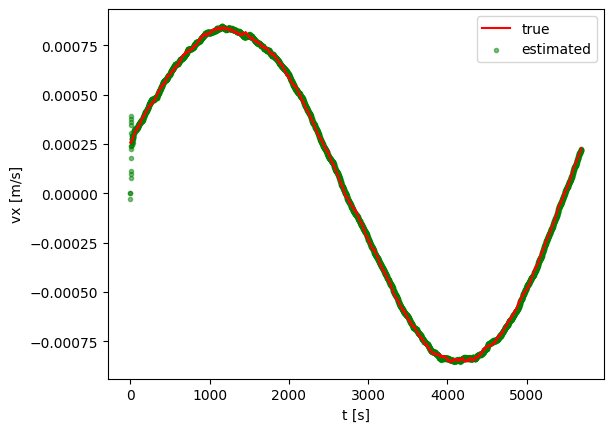

In [36]:
plt.plot(times, states_w_rf[:,3], label="true", color="r")
plt.scatter(times, states_est[:,3], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")

print(f"RMS postion error {RMS(states_est[:,0:3] - states_w_rf[:,0:3])*1e3:.3f} mm")
print(f"RMS velocity error {RMS(states_est[:,3:6] - states_w_rf[:,3:6])*1e3:.4f} mm/s")

## 4. Closing the loop with continous controller (e.g., reaction wheels torque)

### 4.1 Continous control (e.g., reaction wheels)

**Team 5:** the follower's cold-gas thrusters (VACCO MiPS, 10 mN), treated as continuous first; the 30 s pulsed version is in the next cell.

You can try the control laws such as PID from your controls class.

First, test the controller *as if* the state (position, velcoity) are known.

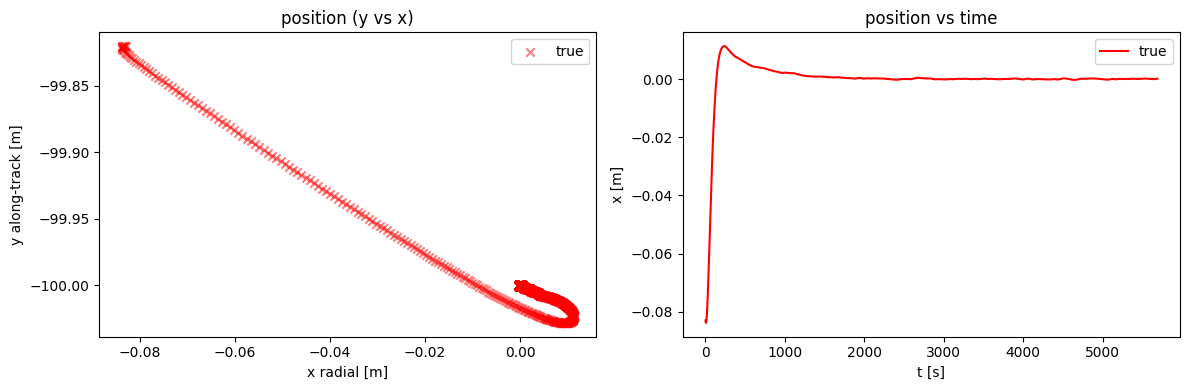

In [ ]:
A = 1e-6 #[m/s^(3/2)] same as above (already realistic, so no reduction needed)
dt = 1
a_std = A/np.sqrt(dt)
##Make distinction very clear between what measurement error
target_pos = r_target # [m] what state you want to control to (science station, 100 m behind the leader)

N = int(5690/dt) #remember to update number of points (one orbit)
times = np.arange(N)*dt

positions_w_rf = np.empty((N, 3))
velocities_w_rf = np.empty((N, 3))

positions_w_rf[0] = r_target + np.random.normal(0,0.1,3)
velocities_w_rf[0] = np.random.normal(0,0.25e-3,3)

#PID gains (tuned: ~4.4 min closed-loop period, damping ~0.7)
K_P = 5.6e-4 #[1/s^2]
K_I = 1e-6 #[1/s^3]
K_D = 1/30 #[1/s]

control = np.zeros(3) #already in units of acceleration for this example only
err_integral = np.zeros(3)

for i in range(N-1):
    # simulated dynamics
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    acceleration_w_rf += control #control added here
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    #control computataion
    err_integral += (positions_w_rf[i+1] - target_pos)*dt
    control = -K_P*(positions_w_rf[i+1] - target_pos) - K_I*err_integral - K_D*velocities_w_rf[i]


plt.figure(figsize=(12,4))

plt.subplot(121)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker="x", alpha=0.5, label="true", color="r")
plt.legend()
plt.xlabel("x radial [m]")
plt.ylabel("y along-track [m]")
plt.title("position (y vs x)")
plt.subplot(122)

plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")

plt.tight_layout()

Once the controller is working, add real-world complications such as noisy measurment and actuator saturation.

30s control cycle, laser noise, whole 2 mN·s impulse bits (SR-08) and 10 mN thrust saturation.

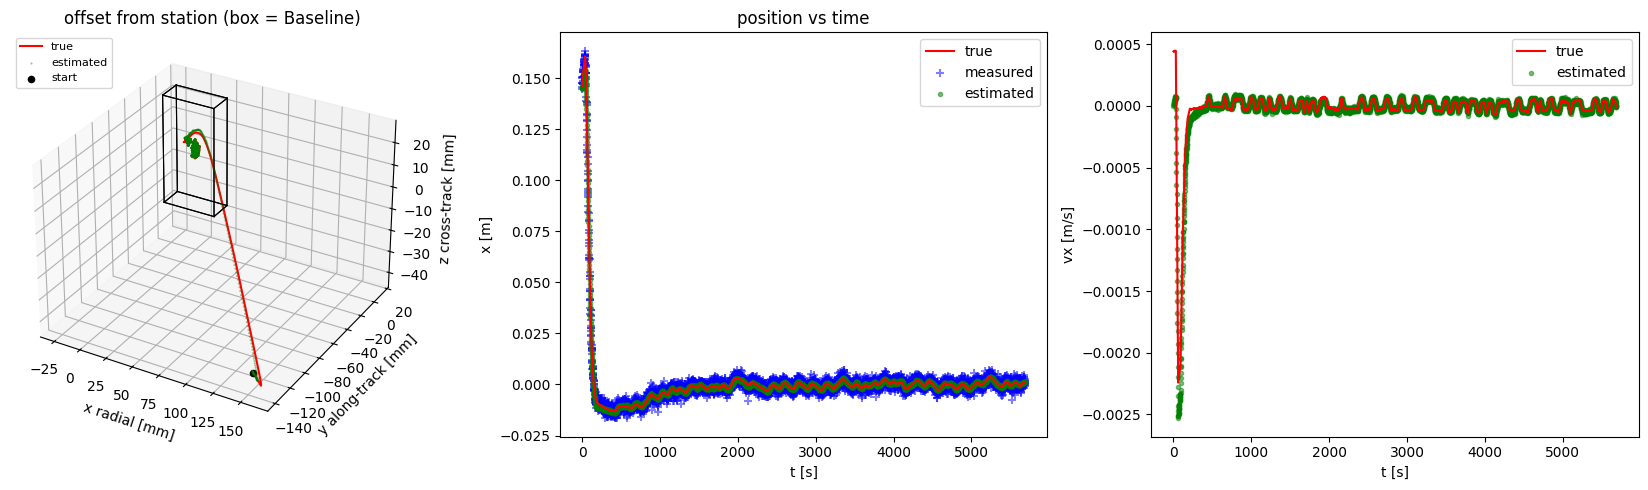

In [38]:
sigma_xy = np.array([5.5e-3, 0.5e-3, 5.5e-3])/3 #[m] laser metrology error (1 sigma), same as 3.1

positions_w_rf[0] = r_target + np.random.normal(0,0.1,3)
velocities_w_rf[0] = np.random.normal(0,0.25e-3,3)

positions_m = np.zeros((N, 3))
   
positions_est = np.zeros((N, 3))
velocities_est = np.zeros((N, 3))
positions_m[0] = positions_w_rf[0] + np.random.normal(0, sigma_xy, 3) #first laser reading
positions_est[0] = positions_m[0] #start the estimate from it

controls_mag = np.zeros(N)
max_control = 10e-3/22.5 #m/s^2 (10 mN thruster on 22.5 kg design mass)

T_ctrl = 30 #[s] control cycle (SR-04)
dv_bit = 2e-3/22.5 #[m/s] one 2 mN-s impulse bit on 22.5 kg (SR-08) = 0.089 mm/s

target_pos = r_target

#PID gains (tuned)
K_P = 5.6e-4
K_I = 1e-6
K_D = 1/30

control = np.zeros(3) #already in units of acceleration for this example only
err_integral = np.zeros(3)

for i in range(N-1):
    # simulated dynamics
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    acceleration_w_rf += control #control added here
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    #measurement(s)
    positions_m[i+1] = positions_w_rf[i+1] + np.random.normal(0, sigma_xy, positions_w_rf[i+1].shape)

    #estimate acceleration using the equation of motion
    acceleration_est = get_acceleration(positions_est[i], velocities_est[i], i*dt)
    acceleration_est += control #control also added here

    #predict position and velocity based on estimates
    position_prediction = positions_est[i] + velocities_est[i]*dt
    velocity_prediction = velocities_est[i] + acceleration_est*dt

    #old velocity estimate
    velocity_num_der = (positions_m[i+1] - positions_m[i])/dt
    #NOTE: if velocity is measured, take a weighted average fo the velocity measurement and the numerical derivative

    #update position and velocity based on measurement AND analytic prediction
    positions_est[i+1] = K_pos*positions_m[i+1] + (1-K_pos)*position_prediction
    velocities_est[i+1] = K_vel*velocity_num_der + (1-K_vel)*velocity_prediction

    #control computataion, once per 30 s control cycle
    #IMPORTANT: use estimates here, not simulated position
    if (i+1) % int(T_ctrl/dt) == 0:
        err_integral += (positions_est[i+1] - target_pos)*T_ctrl
        control = -K_P*(positions_est[i+1] - target_pos) - K_I*err_integral - K_D*velocities_est[i]

        #whole impulse bits only: the delta-V for this cycle (control*T_ctrl) is rounded to a multiple of dv_bit
        control = np.round(control*T_ctrl/dv_bit)*dv_bit/T_ctrl

        control_mag = np.linalg.norm(control)

        #check if controller is saturated
        if control_mag > max_control:
            control = control*(max_control/control_mag)

    controls_mag[i+1] = np.linalg.norm(control)



plt.figure(figsize=(17,5))

ax = plt.subplot(131, projection="3d") #3D, offset from the station in mm
ax.plot(*((positions_w_rf - target_pos)*1e3).T, label="true", color="r")
ax.scatter(*((positions_est - target_pos)*1e3).T, marker=".", s=2, alpha=0.3, label="estimated", color="g")
ax.scatter(*(positions_w_rf[0] - target_pos)*1e3, color="k", marker="o", label="start")
box = np.array([[bx, by, bz] for bx in (-25, 25) for by in (-9, 9) for bz in (-25, 25)]) #Baseline box: lateral x, z +/-25 mm (MR-04), along-track y +/-9 mm (MR-03)
for p in box:
    for q in box:
        if np.sum(p != q) == 1: ax.plot(*zip(p, q), color="k", lw=0.8) #box edges
plt.legend(loc="upper left", fontsize=8)
ax.set_xlabel("x radial [mm]")
ax.set_ylabel("y along-track [mm]")
ax.set_zlabel("z cross-track [mm]")
plt.title("offset from station (box = Baseline)")
plt.subplot(132)

plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.scatter(times, positions_m[:,0], label="measured", color="b", marker="+", alpha=0.5)
plt.scatter(times, positions_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")

plt.subplot(133)
plt.plot(times, velocities_w_rf[:,0], label="true", color="r")
plt.scatter(times, velocities_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")


plt.tight_layout()

Fincally, calcualte closed-loop performace

In [39]:
N_last = int(24*60/dt) #take the last 24 min (MR-01 Baseline hold; the controller has converged by then)

print(f"Standard deviation of closed-loop position [x, y, z] {np.round(np.std(positions_w_rf[-N_last:] - target_pos, axis=0)*1e3, 2)} [mm]")
print(f"Standard deviation of closed-loop velocity [x, y, z] {np.round(np.std(velocities_w_rf[-N_last:], axis=0)*1e3, 3)} [mm/s]  (MR-05 Baseline: 0.15 mm/s)")
print(f"Largest position error [x, y, z] {np.round(np.max(np.abs(positions_w_rf[-N_last:] - target_pos), axis=0)*1e3, 1)} [mm]  (MR-03 along-track y: 9 mm; MR-04 lateral x, z: 25 mm at 100 m; Baseline)")
print(f"Delta-V used over the whole run {np.sum(controls_mag)*dt*1e3:.1f} [mm/s]")

Standard deviation of closed-loop position [x, y, z] [1.39 1.47 1.1 ] [mm]
Standard deviation of closed-loop velocity [x, y, z] [0.037 0.027 0.028] [mm/s]  (MR-05 Baseline: 0.15 mm/s)
Largest position error [x, y, z] [3.9 3.9 3.4] [mm]  (MR-03 along-track y: 9 mm; MR-04 lateral x, z: 25 mm at 100 m; Baseline)
Delta-V used over the whole run 20.0 [mm/s]


#### 4.2 Closing the loop with impulsive control (e.g., propulsive bursts)

The assumption here is that equaitons of motion have a closed form solution (e.g., Clohessy–Wiltshire equations)

a) Write a function that, given a target position, current position, and velocity, computes:
<ul>
 <li>the 3D delta-V that changes the object's velcoity such that it reaches the target position (need to invert the equations of motion)</li>

 <li>the time at which the object will be at the target position</li>

 <li>the thrust neccesary to bring the object to rest once it reaches the desired position</li>
</ul>

b) Simulate this two step control *as if* you have the perfect knowledge of the position and velocity:
<ul>
 <li>run the simulation at with a fine time increments</li>

 <li>at a predefined time step, call the function you wrote in (a)</li>

 <li>add the computed delta-V to the object's velocity</li>

 <li>apply delta-V again after the appropriate number of time steps to bring the object to rest</li>

 <li>test your simulation throughouly to make sure it works in this idealized case</li>
 </ul>


c) Add realistic complications (one at a time):
<ul>

 <li>add measuremnt noise and estimation (don't forget to update your estimated velocity with the delta-V)</li>

 <li>add thruster uncertainties such as burn orientation, magnitude</li>

 <li>add thurst saturation and minimum impulse bit</li>

 <li>test thorughouly and measure closed-loop performance</li>
</ul>

d) Improve performance:
<ul>
 <li>update the last burn to use the estimated velocity</li>

 <li>update the code to more than just two impulses (call the funciton from (a) several times)</li>
</ul>